# Randomized sensing pulse design
Enter known frequencies and hardware timings, generate a random pulse pool,
and export a phase-locked or freely running acquisition. After collecting counts, choose
which observables to evaluate. You can change those weights and reuse the same
saved data for decoding and validation.

For phase-locked experiments, enter raw averages in `[-1,1]` directly or use
the averages CSV. Integer positive-count CSVs remain supported.

RQS uses approximate moment inversion in both field modes. RQS-ML (phase-locked)
or TIMESTAMPED-ML (free-running) optionally refines it using actual responses. Neither result has a certified confidence interval.
All frequencies are in Hz and times in seconds.

In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

candidates = [p for parent in (Path.cwd(), *Path.cwd().parents)
              for p in (parent, parent / "Algorithmic_Sensing_Toolkit")]
ROOT = next(p for p in candidates if (p / "src/randomized_sensing").is_dir())
sys.path.insert(0, str(ROOT / "src"))
# Refresh this package when rerunning after local code edits.
for name in tuple(sys.modules):
    if name.split(".")[0] in ("randomized_sensing", "matched_sensing"):
        del sys.modules[name]
importlib.invalidate_caches()
import randomized_sensing as R
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Specify frequencies and hardware

The field is $b(t)=\sum_j[a_j\cos(2\pi f_jt)+b_j\sin(2\pi f_jt)]$ and
$H=(2\pi\,\mathrm{coupling\_hz})b(t)Z/2$. The amplitude vector $A$ contains
all cosine amplitudes followed by all sine amplitudes.

List **all** possible input frequencies. They need not be equally spaced;
DC is currently unsupported. Observable weights are chosen in step 6,
after the acquisition. No observables enter these experiment settings.

In [2]:
experiment = R.Experiment(
    frequencies_hz=(.8e6, 1.05e6, 1.31e6, 1.72e6),
    coupling_hz=100e3,
    t2_s=200e-6,             # None removes dephasing
    amplitude_bound=1.,     # bound on ||all cosine and sine amplitudes||_2
    min_gap_s=20e-9,
    edge_guard_s=20e-9,
    clock_s=2.5e-9,          # actual hardware timing grid; None permits a numerical design grid
    visibility=1.,
    readout_bias=0.,         # calibrated additive offset in the RAW +/-1 mean
    overhead_s=0.,          # preparation/reset/readout time per shot
)

FIELD_MODE = "phase_locked"  # choose "free_running" to use actual per-shot timestamps, choose phase_locked if you have reset and want to start from the same reference
SHOT_PERIOD_S = 20.0375e-6   # freely running schedule: sensing + preparation/readout/reset

## 2. Build and inspect random pulses

Random multisine phases are uniform on $[0,2\pi)$. Short runs are merged,
then responses are integrated over the actual intervals. The pool contains
independent patterns and their negatives. `pool_size` defaults to
`max(8192, 64*N)`; half that many patterns are independently generated.

The hardware clock takes precedence over `design_clock_s`. Every interval
conservatively obeys `max(min_gap_s, edge_guard_s)`, rounded **up** to the grid.
The duration must contain a whole number of grid cells. `max_pulses` rejects
longer pulse trains. These settings can affect the response distribution.

`start_time_s` defines the reference time for the stored pulse responses.
In `phase_locked` mode, each shot reproduces those starting tone phases.
In `free_running` mode, the same waveforms run at different phases and the
decoder rotates each response using its measured sensing-start timestamp.
Use a common stable clock origin; an unknown initial source phase is absorbed
into the Fourier amplitudes. Source reset is unnecessary in freely running mode.

In [3]:
pool = R.build_pool(
    experiment,
    duration_s=20e-6,
    max_pulses=64, #use None if you do not have an additional tighter limit on the pulse count
    pool_size=None,
    start_time_s=123e-9,
    design_clock_s=2.5e-9,   # numerical grid only when experiment.clock_s is None
    seed=4,
)
checks = [R.audit(pool, i) for i in range(len(pool.sequences))]
assert all(c["timing_valid"] for c in checks)
print(f"Pool: {len(pool.Z)} signed responses; {len(pool.sequences)} independent patterns")
print(f"Actual design grid: {pool.design_clock_s*1e9:g} ns")
print(f"Smallest interval: {min(c['minimum_interval_s'] for c in checks)*1e9:.3f} ns")
print(f"Largest pulse count: {max(c['pulse_count'] for c in checks)}")
print(f"Covariance condition number: {pool.condition:.3f}")
print("Synthesis method:", pool.synthesis_method)

Pool: 8192 signed responses; 4096 independent patterns
Actual design grid: 2.5 ns
Smallest interval: 20.000 ns
Largest pulse count: 60
Covariance condition number: 1.335
Synthesis method: dense


### Automatic FFT acceleration

`pool.synthesis_method` reports `"fft"` on compatible frequencies and `"dense"`
for arbitrary tones. Both integrate the repaired cells exactly. This small
example changes the demo frequencies to a compatible grid and uses four FFT
workers inside a local context. It does not replace the main experiment/pool.

Long commensurate shots automatically use the multisine's natural period for
FFT computation. The complete requested waveform still undergoes timing repair,
and exact integration includes boundary changes and partial final periods.

In [4]:
from dataclasses import replace
from scipy.fft import set_workers
from time import perf_counter

fft_experiment = replace(experiment, frequencies_hz=(.8e6, 1.05e6, 1.3e6, 1.7e6))
before = perf_counter()
with set_workers(4):
    fft_example = R.build_pool(fft_experiment, duration_s=20e-6, pool_size=128,
                               max_pulses=64, start_time_s=123e-9, seed=4)
print(f"Small example: {fft_example.synthesis_method}, {perf_counter()-before:.3f} s, "
      f"condition={fft_example.condition:.2f}")

Small example: fft, 0.014 s, condition=3.43


### Detect an unresolved design before acquisition

`min_spacing * duration_s < 1` warns before synthesis. Covariance condition
above 20 warns; above 1000 rejects a new build. Here two tones only 1 kHz
apart are deliberately unresolved by a 20 us shot. The example catches the
error and warnings so the walkthrough can continue. Increase the duration,
separate the tones, relax timing, or increase an undersized pool before use.

`allow_ill_conditioned=True` permits inspection with warnings; it does not
repair an unstable design or certify accuracy. Existing saved bundles load
with a warning rather than the new build-time rejection.

In [5]:
import warnings

unresolved = replace(experiment, frequencies_hz=(1e6, 1.001e6))
with warnings.catch_warnings(record=True) as notices:
    warnings.simplefilter("always")
    try:
        R.build_pool(unresolved, duration_s=20e-6, pool_size=128, seed=4)
    except ValueError as error:
        print("Rejected design:", error)
for notice in notices:
    print("Design warning:", notice.message)

Rejected design: Pool covariance condition 2.52e+06 exceeds 1000; increase duration, separate tones, or relax timing. Set allow_ill_conditioned=True only to inspect this unstable design.
Design warning: Minimum tone spacing * duration_s is below 1: tones may be unresolved and estimates ill-conditioned. Increase duration or separate the tones; inspect pool.condition.


Y outcome sign: -1


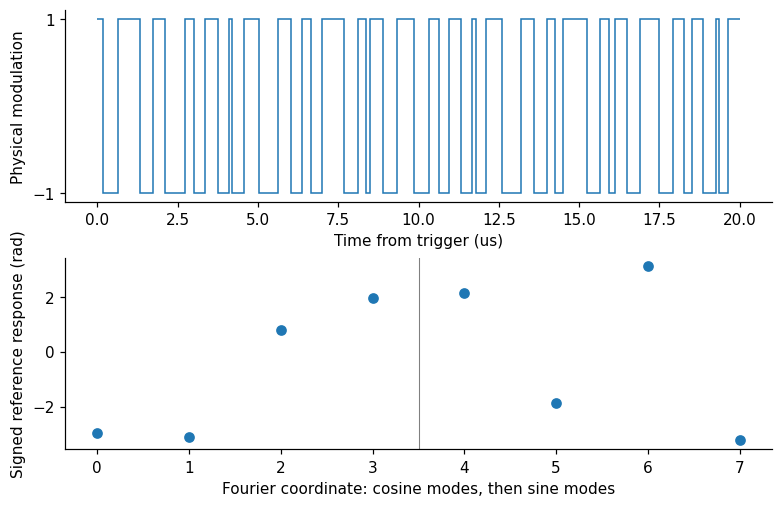

In [6]:
index = 1
sequence = pool.sequence(index)
edges = np.r_[0., sequence.switch_times_s, pool.duration_s]
fig, axes = plt.subplots(2, 1, figsize=(7, 4.5), constrained_layout=True)
axes[0].stairs((-1.)**np.arange(len(edges)-1), edges*1e6, baseline=None)
axes[0].set(xlabel="Time from trigger (us)", ylabel="Physical modulation", yticks=[-1, 1])
axes[1].plot(np.arange(2*pool.N), pool.Z[index], "o")
axes[1].axvline(pool.N-.5, color="grey", lw=.7)
axes[1].set(xlabel="Fourier coordinate: cosine modes, then sine modes", ylabel="Signed reference response (rad)")
print("Y outcome sign:", R.audit(pool, index)["y_outcome_sign"])
plt.show()

## 3. Freeze a shot budget

Entries are drawn uniformly with replacement for X and Y shots. `n_shots` includes
both bases and is a chosen budget, not a promised precision. T2 enters the shot
contrast; duration is an explicit choice and is not optimized here.

- `phase_locked`: repeated sequence/basis pairs are grouped into count rows.
- `free_running`: one row per shot, random X/Y interleaving, and a nominal start
  schedule using `SHOT_PERIOD_S`. The period includes sensing plus reset/readout
  time. You can instead supply a full `start_times_s` schedule to `plan_acquisition`.

Measured timestamps are recorded later; they can differ from the planned schedule.

A freely running regular period that repeats every tone phase triggers a
warning: timestamps then add no phase diversity. The example
`SHOT_PERIOD_S=20.0375e-6` avoids that commensurability. Actual timestamps and
the decoder's full-rank check still determine whether the design is usable.

In [7]:
timing_options = (dict(shot_period_s=SHOT_PERIOD_S)
                  if FIELD_MODE == "free_running" else {})
plan = R.plan_acquisition(pool, n_shots=20_000, x_fraction=.2, seed=5,
                          field_mode=FIELD_MODE, **timing_options)
print("Field mode:", plan.field_mode)
print(f"Planned shots: {plan.total_shots:,}; acquisition rows: {len(plan.rows):,}")
print(f"Expected contrast: {experiment.contrast(pool.duration_s):.4f}")
print(f"Planned active sensing: {plan.active_time_s*1e3:.2f} ms")
print(f"Including specified per-shot overhead: {plan.time_with_overhead_s*1e3:.2f} ms")
if plan.scheduled_span_s is not None:
    print(f"Scheduled first-start to last-end span: {plan.scheduled_span_s*1e3:.2f} ms")
    print("This span excludes final readout overhead; record actual starts during acquisition.")
else:
    print("Additional phase-reference waits are not included.")

Field mode: phase_locked
Planned shots: 20,000; acquisition rows: 10,240
Expected contrast: 0.9048
Planned active sensing: 400.00 ms
Including specified per-shot overhead: 400.00 ms
Additional phase-reference waits are not included.


## 4. Export for hardware

`pulses.csv` lists only internal X(pi) pulses. Physical modulation always starts
at +1, including negative pool entries; no extra initial or final pulse is needed.
The decoder handles virtual response signs and odd-pulse Y-frame parity using
`outcome_sign` in `acquisition.csv`.

Read `RUN.txt`, implement its physical X/Y measurement convention, and fill a
**copy** of `averages_template.csv` with raw means in `[-1,1]` and repetition
counts. `counts_template.csv` remains available for integer +1 counts. Do not apply sign
corrections or subtract the readout bias yourself. Each average belongs to one
sequence **and measurement basis**; its repetitions must share starting phases. Re-executing the next cell
replaces generated bundle files; save measured counts separately.

For `free_running`, each row is a single shot. Record both its raw `plus`
outcome (0 or 1) and its **actual** `start_time_s` in the counts CSV. The
exported `planned_start_time_s` is only a nominal schedule. Use elapsed seconds
from one stable clock origin, not Unix timestamps; timestamp precision must
resolve the fastest tone. Do not group shots taken at different times.

In [8]:
folder = "randomized_free_running_example" if FIELD_MODE == "free_running" else "randomized_example"
output = R.export_bundle(plan, ROOT / "outputs" / folder, overwrite=True)
files = ["sequences.csv", "pulses.csv", "intervals.csv", "acquisition.csv",
         "counts_template.csv", "bundle.json", "pool.npz", "manifest.json", "RUN.txt"]
if FIELD_MODE == "phase_locked":
    files.append("averages_template.csv")
for name in files:
    print((output / name).relative_to(ROOT))

outputs/randomized_example/sequences.csv
outputs/randomized_example/pulses.csv
outputs/randomized_example/intervals.csv
outputs/randomized_example/acquisition.csv
outputs/randomized_example/counts_template.csv
outputs/randomized_example/bundle.json
outputs/randomized_example/pool.npz
outputs/randomized_example/manifest.json
outputs/randomized_example/RUN.txt
outputs/randomized_example/averages_template.csv


## 5. Optional simulated measurement

This example uses a dense field of norm 0.5. The simulation uses the actual
repaired responses and calibrated dephasing/readout model. The decoder receives
only the saved plan and counts. Skip this cell when using hardware data.

For freely running mode, the demo adds small synthetic trigger delays and saves
the actual timestamps with the outcomes. Hardware must supply its measured
sensing-start timestamps from the acquisition clock.

In phase-locked mode, the demo also saves means computed from those same
binary counts. Decoding the counts or their unrounded means gives the same
estimator. You can replace the demo means with your experimental averages.

In [9]:
rng = np.random.default_rng(4)
amplitudes = rng.normal(size=2*pool.N)
amplitudes *= .5*experiment.amplitude_bound/np.linalg.norm(amplitudes)
actual_starts = None
if plan.field_mode == "free_running":
    scheduled_starts = np.array([row["start_time_s"] for row in plan.rows])
    actual_starts = scheduled_starts + rng.uniform(0., 10e-9, len(plan.rows))
demo_counts = R.simulate(plan, amplitudes, seed=42, start_times_s=actual_starts)
R.write_counts(output / "demo_counts.csv", plan, demo_counts)
print("Saved simulated RAW counts to", output / "demo_counts.csv")
if plan.field_mode == "phase_locked":
    demo_averages = [2*demo_counts[row["row_id"]]/row["shots"]-1 for row in plan.rows]
    R.write_averages(output / "demo_averages.csv", plan, demo_averages)
    print("Saved mean-valued data to", output / "demo_averages.csv")

Saved simulated RAW counts to /Users/aditi/Documents/Numerics/Algorithmic Spectroscopy/Algorithmic_Sensing_Toolkit/outputs/randomized_example/demo_counts.csv


Saved mean-valued data to /Users/aditi/Documents/Numerics/Algorithmic Spectroscopy/Algorithmic_Sensing_Toolkit/outputs/randomized_example/demo_averages.csv


## 6. Choose observables after acquisition

Each row below defines $F_j=\sum_k c_{jk}a_k+s_{jk}b_k$. Columns follow the
frequency order in step 1. Use matching `(N,)` vectors for one observable or
`(M,N)` arrays for several. Add, remove, or change rows as needed.

**To try different observables, edit this cell and rerun steps 6 onward.**
The pulse pool, exported acquisition, and measured counts are reused.

In [10]:
# Edit these weights freely after collecting the data.
cosine_weights = np.array([[.5, -.3, 0., .4], [.1, .2, -.4, .3]])
sine_weights = np.array([[.2, .4, .1, -.2], [-.3, .1, .2, .25]])
observable_weights = dict(cosine_weights=cosine_weights, sine_weights=sine_weights)

## 7. Decode the selected observables

For phase-locked measurements, choose `INPUT_FORMAT="averages_csv"` and select
your completed average CSV below. To paste a list such as `[0.54, -0.1, ...]`,
choose `"values"` and supply the full `mean_values` array in **acquisition.csv
row order**. Its length must be `len(saved_plan.rows)`; X and Y rows are separate.
Rounded values in `[-1,1]` are accepted. Set `repetitions` to your averaging
count (one integer for all rows, an array, or a row-ID mapping); `None` uses the
planned counts. Raw means receive bias and pulse-sign corrections in the decoder.

`"counts_csv"` retains the original positive-count interface. RQS moment inversion
and RQS-ML refinement accept either phase-locked representation. The RQS moment
weights remain the frozen random-draw multiplicities, while actual repetitions
weight optional likelihood refinement. `floor_active=True` exposes the small-X guard.
Plan resource totals are planned costs; actual repetition counts determine actual time.

Freely running data retain `"counts_csv"` and use **RQS by default**, with actual
per-shot timestamps. It whitens each response in the bank frame before rotating
the back-projection, then uses the shared X-mean guard and per-tone correction.
Only one X and one Y shot are required. Optional TIMESTAMPED-ML adds the moment
estimate as a fourth likelihood starting point. Below `6*N` shots or with
insufficient Y rank it returns RQS with `ml_applied=False` and a
`refinement_skipped_reason`. Missing timestamps and actual fit failures still
raise errors. Averages across different starting phases are not accepted.

For continuous readout at known phases, choose `"timed_values"` below and fill
`raw_values` and `actual_start_times` in acquisition row order. Direct library use is
`R.decode(saved_plan, R.TimedOutcomes(raw_values, actual_start_times))`, with one
raw value in `[-1,1]` per acquisition row. Each value must belong to its one
recorded starting phase.

Weights are applied after amplitude reconstruction; changing them reuses the
same data. No certified confidence intervals or global-optimum guarantee are claimed.

For direct library use, `R.decode_averages` accepts either an ordered array or
a row-ID mean mapping:

```python
result = R.decode_averages(saved_plan, mean_values, repetitions=100, **observable_weights)
```

In [11]:
INPUT_FORMAT = "averages_csv" if FIELD_MODE == "phase_locked" else "counts_csv"
# To enter experimental averages directly, select "values" and fill this array.
mean_values = None  # full list of raw means in acquisition.csv row order
repetitions = None  # e.g. 100 for every row; None uses the plan's shot counts
# Free-running continuous readout: select "timed_values" and fill both arrays.
raw_values = None  # one raw value in [-1,1] per row, e.g. [0.54, -0.1, ...]
actual_start_times = None  # one measured elapsed time in seconds per row

data_file = output / ("demo_averages.csv" if INPUT_FORMAT == "averages_csv" else "demo_counts.csv")
# Replace data_file with your completed hardware CSV when using CSV input.
saved_plan = R.load_bundle(output)
if INPUT_FORMAT == "averages_csv":
    outcomes = R.read_averages(data_file, saved_plan)
elif INPUT_FORMAT == "values":
    if mean_values is None:
        raise ValueError("Fill mean_values with one raw mean per acquisition.csv row.")
    outcomes = R.AveragedOutcomes(mean_values, repetitions)
elif INPUT_FORMAT == "timed_values":
    if raw_values is None or actual_start_times is None:
        raise ValueError("Fill raw_values and actual_start_times for every acquisition row.")
    outcomes = R.TimedOutcomes(raw_values, actual_start_times)
elif INPUT_FORMAT == "counts_csv":
    outcomes = R.read_counts(data_file, saved_plan)
else:
    raise ValueError("Choose averages_csv, values, counts_csv, or timed_values.")

methods = ("RQS", "TIMESTAMPED-ML") if saved_plan.field_mode == "free_running" else ("RQS", "RQS-ML")
results = {method: R.decode(saved_plan, outcomes, method=method, **observable_weights)
           for method in methods}
for method, result in results.items():
    print(method)
    for j, value in enumerate(result.values, start=1):
        print(f"  F{j}: {value:.6f}")
    if result.guard_floor is not None:
        print(f"  X mean={result.x_mean:.4f}, guard={result.guard_floor:.4f}, floor active={result.floor_active}")
    if result.fit_converged is not None:
        print(f"  Fit converged={result.fit_converged}; Y-response condition={result.response_condition:.3f}")
    print(f"  Likelihood applied={result.ml_applied}, fitted contrast={result.fitted_contrast}")
    if result.refinement_skipped_reason:
        print("  Refinement skipped:", result.refinement_skipped_reason)
if isinstance(outcomes, (R.TimedCounts, R.TimedOutcomes)):
    from collections.abc import Mapping
    measured_times = outcomes.start_times_s
    actual_times = np.array([measured_times[row["row_id"]] for row in saved_plan.rows]
                            if isinstance(measured_times, Mapping) else measured_times)
    span = actual_times[-1]-actual_times[0]+saved_plan.pool.duration_s
    print(f"Measured first-start to last-end span: {span*1e3:.2f} ms (excludes final readout)")

RQS
  F1: -0.082391
  F2: -0.029198
  X mean=0.3275, guard=0.0190, floor active=False
  Likelihood applied=False, fitted contrast=None
RQS-ML
  F1: -0.080370
  F2: -0.029361
  X mean=0.3275, guard=0.0190, floor active=False
  Likelihood applied=True, fitted contrast=0.9096640195489747


## 8. Optional validation on a known synthetic field

Run these cells only after the simulation cell. In phase-locked mode, population
moments expose RQS approximation error without shot noise. In freely running
mode, exact expected outcomes at the measured timestamps pass through RQS.
This removes binary outcome noise while retaining finite waveform/schedule
sampling variation. Pass `method="TIMESTAMPED-ML"` to `population_estimate` for
the optional likelihood check, with the same fallback rules.

The second check repeats independent noisy measurements. Both checks use the
current weights from step 6 and the same actual timestamp table when present.
They do not prove performance for every input field or schedule. For hardware
data without known truth, skip this section.

RQS-population noise-free error per query: [-0.00650123  0.00356085]


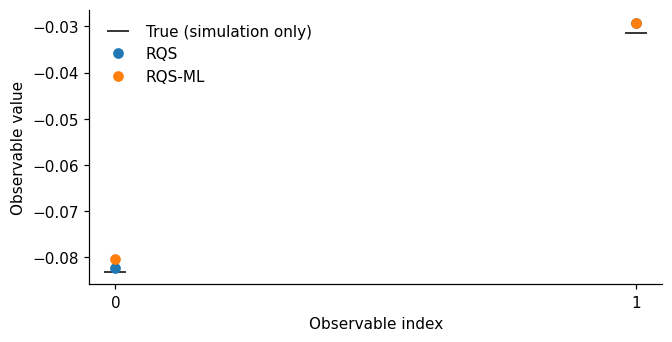

In [12]:
# Remove outcome noise while retaining this field and the actual timing table.
validation_timing = (dict(start_times_s=outcomes.start_times_s)
                     if isinstance(outcomes, R.TimedCounts) else {})
population = R.population_estimate(saved_plan, amplitudes, **observable_weights, **validation_timing)
truth = np.asarray(R.evaluate_observables(amplitudes, **observable_weights))
print(population.method, "noise-free error per query:", np.asarray(population.values)-truth)

fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
x = np.arange(len(truth))
ax.plot(x, truth, "k_", ms=15, label="True (simulation only)")
for method, result in results.items():
    ax.plot(x, result.values, "o", label=method)
ax.set(xlabel="Observable index", ylabel="Observable value", xticks=x)
ax.legend(frameon=False)
plt.show()

In [13]:
RUN_REPEATED_TRIALS = False  # optional; evaluates this field and fixed acquisition only
if RUN_REPEATED_TRIALS:
    errors = {method: [] for method in results}
    for seed in range(100, 130):
        trial_counts = R.simulate(saved_plan, amplitudes, seed=seed, **validation_timing)
        for method in errors:
            estimate = R.decode(saved_plan, trial_counts, method=method, **observable_weights)
            errors[method].append(np.max(abs(np.asarray(estimate.values)-truth)))
    for method, values in errors.items():
        print(method, "median / 95th percentile max query error:", np.quantile(values, [.5, .95]))

## 9. Free-running example below the former 6N floor

With 50 tones the full likelihood fit requires at least 300 shots. The moment
estimator can return an estimate from 200 shots. This separate example uses
25 kHz–1.25 MHz tones to fit the walkthrough's pulse-count cap. It inherits the
clock, minimum gap, edge guard and readout parameters, and retains the main
pool's pulse-count cap. It reports the skipped refinement explicitly and makes
no fixed-precision claim for this small shot budget.

In [14]:
from dataclasses import replace

frequencies_50 = tuple(np.arange(1, 51)*25e3)
experiment_50 = replace(experiment, frequencies_hz=frequencies_50, coupling_hz=28e3)
pool_50 = R.build_pool(experiment_50, duration_s=40e-6, pool_size=1024,
                        max_pulses=pool.settings.get("max_pulses"), seed=4)
plan_50 = R.plan_acquisition(pool_50, n_shots=200, field_mode="free_running",
                             shot_period_s=40e-6+experiment_50.overhead_s+1.2345e-6, seed=5)
a_50 = np.random.default_rng(6).normal(size=100)
a_50 *= .2*experiment_50.amplitude_bound/np.linalg.norm(a_50)
counts_50 = R.simulate(plan_50, a_50, seed=42)
for method in ("RQS", "TIMESTAMPED-ML"):
    result_50 = R.decode(plan_50, counts_50, method=method)
    print(method, "shots=200 < 6N=300; ML applied:", result_50.ml_applied)
    if result_50.refinement_skipped_reason:
        print(" ", result_50.refinement_skipped_reason)

RQS shots=200 < 6N=300; ML applied: False
TIMESTAMPED-ML shots=200 < 6N=300; ML applied: False
  Timestamped ML requires at least 3*2N shots and 2N Y shots.


## 10. Scaling checks on held-out signals

The benchmark searches duration/X fraction on 128 calibration signals and
estimates T95 on 400 held-out signals split over two fresh banks. Signals
alternate dense and single-tone cases. It checks no dephasing, T2=1 ms, and a
weak-signal stress test. Timings exclude preparation/readout overhead. Results
include the actual n, duration, success rate, convergence flags, and fitted
slopes; a sqrt(N) slope is an expectation to test.

From the toolkit root, start with the moment estimators:

```sh
PYTHONPATH=src python benchmarks/free_running_scaling.py --ml-trials 0 --output benchmarks/results/free_running_scaling_RQS.json
```

For all likelihood comparisons, run the script with its default `--ml-trials
400` and a separate output path. This additionally evaluates the former
ML-only eligibility restriction and the new optional refinement. Full likelihood
runs can take substantially longer. Completed conditions are checkpointed and
resumed. The cell below displays whatever completed results are available.

A smaller paired likelihood check is available with
`PYTHONPATH=src python benchmarks/free_running_refinement_check.py`. Its four
trials per condition illustrate errors, skipped fits and classical time; they
do not measure T95 or a refinement scaling exponent. The dashed 6N curve is
only an eligibility bound at the plotted durations, not measured ML performance.
It has N^1.5 scaling only when those durations scale as sqrt(N).

Saved reports: [RQS scaling](../benchmarks/results/free_running_scaling_RQS.md) and
[small paired likelihood check](../benchmarks/results/free_running_refinement_check.md).
For implementation checks, see [correctness validation](../benchmarks/validation.md);
exhaustive likelihood scaling is optional.

case       norm   N  tau(us)  X frac   n locked   n free   free success   converged
noiseless  0.65  10       40     0.1       1673     1574          0.943 True
noiseless  0.65  20       80     0.2       1663     1666          0.938 True
noiseless  0.65  50       80     0.1       2550     2700          0.950 True
noiseless  0.65 100      120     0.1       2700     2700          0.948 True
noiseless  0.65 200      200     0.1       2642     2464          0.950 True
noiseless  0.65 300      280     0.1       2502     2502          0.955 True
noiseless  0.65 500      240     0.1       3958     3969          0.955 True
t2_1ms     0.65  10       40     0.1       1950     1846          0.943 True
t2_1ms     0.65  20       40     0.1       3533     3490          0.932 True
t2_1ms     0.65  50       80     0.1       3095     3268          0.955 True
t2_1ms     0.65 100      120     0.1       3510     3510          0.948 True
t2_1ms     0.65 200      200     0.1       3944     3955          0.9

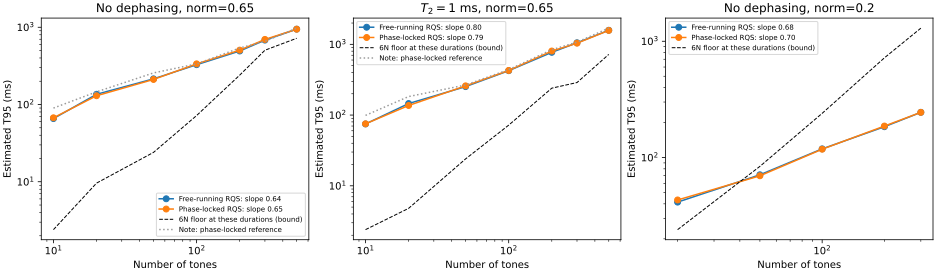

In [2]:
import json
from IPython.display import SVG, display

benchmark_path = ROOT / "benchmarks/results/free_running_scaling_RQS.json"
if benchmark_path.exists():
    benchmark = json.loads(benchmark_path.read_text())
    print("case       norm   N  tau(us)  X frac   n locked   n free   free success   converged")
    for row in benchmark["rows"]:
        if "evaluation" not in row:
            continue
        locked = row["evaluation"]["phase_locked_RQS"]
        free = row["evaluation"]["free_running_RQS"]
        print(f"{row['case']:10s} {row['norm']:.2f} {row['N']:3d} {free['tau_us']:8g} "
              f"{free['x_fraction']:7.1f} {locked['n']:10d} {free['n']:8d} "
              f"{free['success']:14.3f} {free['converged']}")
    if benchmark_path.with_suffix(".svg").exists():
        display(SVG(filename=str(benchmark_path.with_suffix(".svg"))))
else:
    print("Run the benchmark script to generate the scaling report.")

Frequencies and global Fourier amplitudes must remain fixed during acquisition.
Phase-locked mode requires reproducible starting phases; freely running mode
requires accurate timestamps from one stable clock. Finite pulse widths, timing
uncertainty, field drift, and calibration uncertainty are not modeled.
See [randomized protocol and conventions](../docs/randomized.md).